<a href="https://colab.research.google.com/github/AHTISHAM327/gan-dcgan-reproduction/blob/main/ahtisham/00_data_loading.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Setup**

In [1]:
import os, glob, random, shutil
import numpy as np, pandas as pd, torch, torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from torchvision.utils import make_grid, save_image
from PIL import Image
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '| device:', device)

torch 2.11.0+cu130 | device: cuda


## **Mount Drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Helper to show and save a grid of 64 images

In [3]:
os.makedirs('/content/figures', exist_ok=True)
def show_grid(x, title, path):
    grid = make_grid(x[:64], nrow=8, normalize=True, value_range=(-1, 1))
    plt.figure(figsize=(6, 6)); plt.imshow(grid.permute(1, 2, 0).cpu())
    plt.axis('off'); plt.title(title); plt.show()
    save_image(x[:64], path, nrow=8, normalize=True, value_range=(-1, 1))

## **MNIST**(reproduction dataset), loaded from our Drive copy

train: 60000 | test: 10000
batch: (128, 1, 28, 28) torch.float32 | min -1.0 max 1.0


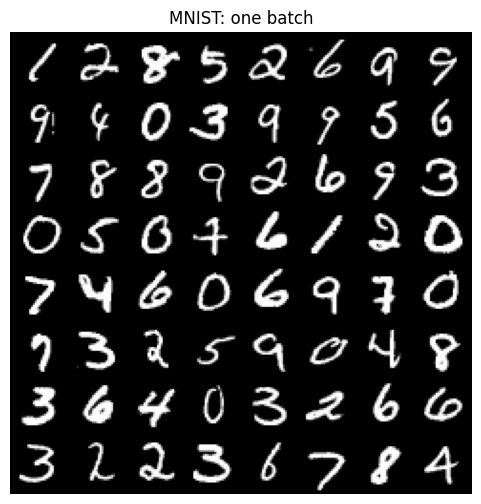

In [4]:
os.makedirs('/content/data/MNIST/raw', exist_ok=True)
!cp /content/drive/MyDrive/gan-dcgan-reproduction-data/data/mnist/*.gz /content/data/MNIST/raw/
mnist_tf = T.Compose([T.ToTensor(), T.Normalize((0.5,), (0.5,))])
mnist_train = torchvision.datasets.MNIST('/content/data', train=True,  download=True, transform=mnist_tf)
mnist_test  = torchvision.datasets.MNIST('/content/data', train=False, download=True, transform=mnist_tf)
mnist_loader = DataLoader(mnist_train, batch_size=128, shuffle=True, num_workers=2)

x, y = next(iter(mnist_loader))
print('train:', len(mnist_train), '| test:', len(mnist_test))
print('batch:', tuple(x.shape), x.dtype, '| min', round(x.min().item(), 2), 'max', round(x.max().item(), 2))
show_grid(x, 'MNIST: one batch', '/content/figures/mnist_batch.png')

## **CelebA**: copy the zip from Drive and unzip

In [6]:
ZIP = '/content/drive/MyDrive/gan-dcgan-reproduction-data/data/celeba-dataset.zip'

# Copy + unzip only once per Colab session (local disk is much faster than reading from Drive)
if not os.path.exists('/content/celeba'):
    shutil.copy(ZIP, '/content/celeba.zip')
    !unzip -q /content/celeba.zip -d /content/celeba

# Find the images folder automatically (the Kaggle zip nests it inside another folder)
img_dir  = os.path.dirname(next(glob.iglob('/content/celeba/**/*.jpg', recursive=True)))
# Official split file: 0 = train, 1 = val, 2 = test
part_csv = glob.glob('/content/celeba/**/list_eval_partition.csv', recursive=True)[0]

print('images folder:', img_dir)
print('split file:', part_csv)

images folder: /content/celeba/img_align_celeba/img_align_celeba
split file: /content/celeba/list_eval_partition.csv


# Our own **CelebA Dataset** class + **DataLoader**

In [ ]:
#Our own Dataset class as required
class CelebAFaces(Dataset):
    """Reads CelebA faces from one official split (0 = train, 1 = val, 2 = test)."""
    def __init__(self, img_dir, partition_csv, split=0, transform=None):
        df = pd.read_csv(partition_csv)
        # Keep only the image names that belong to the chosen split
        self.files = df.loc[df['partition'] == split, 'image_id'].tolist()
        self.img_dir, self.transform = img_dir, transform
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(self.img_dir, self.files[i])).convert('RGB')
        return self.transform(img)

#Crop to the face (178x178), resize to 64x64 (DCGAN size), scale pixels to [-1,1] to match G's tanh output
celeba_tf = T.Compose([T.CenterCrop(178), T.Resize(64), T.ToTensor(),
                       T.Normalize([0.5] * 3, [0.5] * 3)])
celeba_train  = CelebAFaces(img_dir, part_csv, split=0, transform=celeba_tf)
celeba_loader = DataLoader(celeba_train, batch_size=128, shuffle=True, num_workers=2)

# Proof for the lab: count, batch shape, dtype, value range, and a grid of faces
xc = next(iter(celeba_loader))
print('train images:', len(celeba_train))
print('batch:', tuple(xc.shape), xc.dtype, '| min', round(xc.min().item(), 2), 'max', round(xc.max().item(), 2))
show_grid(xc, 'CelebA 64x64: one batch', '/content/figures/celeba_batch.png')

## Download the 2 grids for the proposal **page**

In [8]:
from google.colab import files
files.download('/content/figures/mnist_batch.png')
files.download('/content/figures/celeba_batch.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>